<a href="https://colab.research.google.com/github/SUCCESSneeded/practice/blob/main/Mlmaths.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import random

In [3]:
l=[]
for i in range(10000):
  a=random.randint(1,6)
  b=random.randint(1,6)
  l.append(a+b)

In [4]:
len(l)

10000

In [5]:
l[:5]

[4, 6, 5, 6, 10]

In [6]:
s=(pd.Series(l).value_counts()/pd.Series(l).value_counts().sum()).sort_index()
print(s)

2     0.0267
3     0.0552
4     0.0800
5     0.1077
6     0.1406
7     0.1692
8     0.1411
9     0.1084
10    0.0850
11    0.0559
12    0.0302
Name: count, dtype: float64


<Axes: >

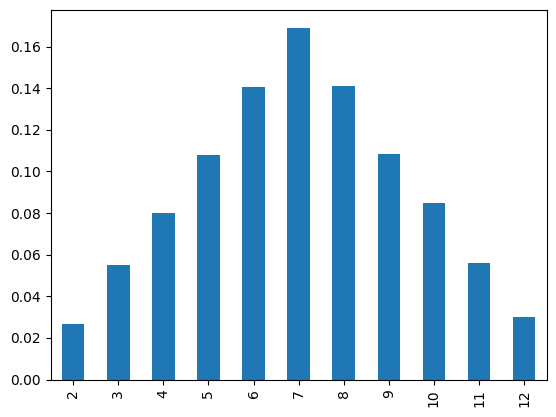

In [7]:
s.plot(kind='bar')

<Axes: >

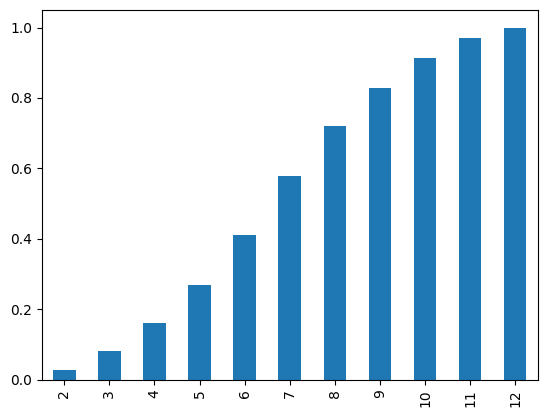

In [8]:
np.cumsum(s).plot(kind='bar')

PARAMETRIC DENSITY ESTIMATION

In [9]:
from numpy.random import normal

sample=normal(loc=50,scale=5,size=1000)
print(sample)
#loc=mean ,scale=std

[54.53866243 48.03142734 50.07081289 53.39550183 51.65545604 52.72434293
 44.48108131 46.62769811 46.43156817 51.8837272  56.11133846 37.85461732
 49.77590874 47.40783847 51.46026137 48.34841441 50.12309144 49.66830515
 50.74988609 45.6761625  47.19356875 46.11261039 51.16311005 46.35949455
 52.7322261  41.56196299 48.18724028 59.77045287 46.26378599 51.39658883
 55.50323397 52.19913835 52.73325851 49.89932887 44.4722916  41.76061775
 53.13322655 48.21345208 42.13451457 57.87253636 55.51139348 44.90628726
 53.85532009 40.16998994 50.30467221 55.96342719 47.2571203  50.35940978
 47.14108371 54.65528017 47.4835817  49.36269148 49.61198416 49.90965695
 45.11339157 49.11823891 54.33213435 39.15777814 51.28976687 46.01955207
 49.24700664 59.23865187 40.70868179 52.20177193 36.40667886 41.1077995
 48.57446052 54.30094792 46.81672587 48.41206027 45.21641603 52.87564769
 46.4899527  52.56377353 47.85861984 44.87898864 49.21858453 51.07661907
 47.02643008 44.20949934 42.71273719 48.63905941 56.

In [10]:
sample.mean()

np.float64(50.00852682040766)

(array([ 11.,  53.,  93., 178., 267., 191., 131.,  59.,  14.,   3.]),
 array([35.53971173, 38.65742029, 41.77512886, 44.89283743, 48.010546  ,
        51.12825457, 54.24596313, 57.3636717 , 60.48138027, 63.59908884,
        66.71679741]),
 <BarContainer object of 10 artists>)

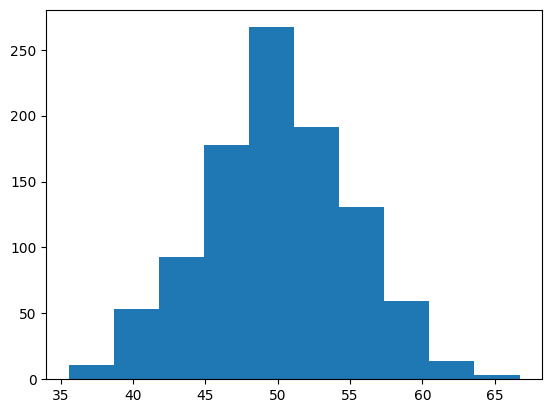

In [11]:
plt.hist(sample,bins=10)

In [12]:
sample_mean=sample.mean()
sample_std=sample.std()

In [13]:
from scipy.stats import norm
dist=norm(sample_mean,sample_std)

In [14]:
sample.min()

np.float64(35.539711725120966)

In [15]:
sample.max()

np.float64(66.7167974068498)

In [16]:
# generating 100 datapts
values=np.linspace(sample.min(),sample.max(),100)

In [17]:
probabilities=[dist.pdf(value) for value in values]

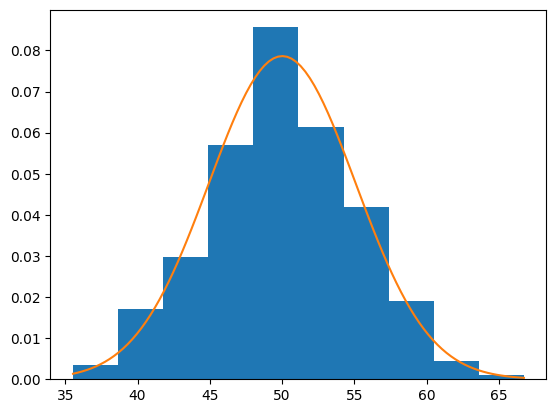

In [18]:
plt.hist(sample,bins=10,density=True)
plt.plot(values,probabilities)

/tmp/ipykernel_445/1482356190.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sample)


<Axes: ylabel='Density'>

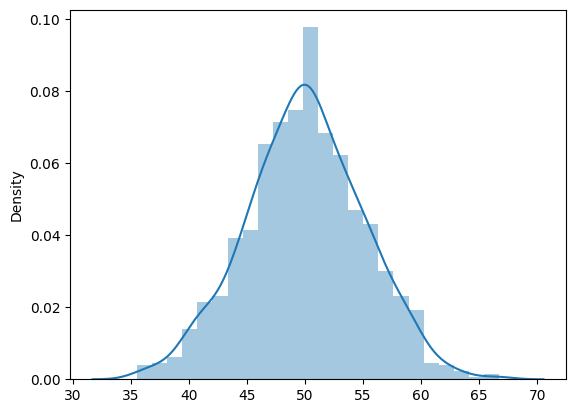

In [19]:
import seaborn as sns
sns.distplot(sample)

KDE

In [20]:
sample1=normal(loc=20,scale=5,size=300)
sample2=normal(loc=40,scale=5,size=700)
sample=np.hstack((sample1,sample2))

In [21]:
sample

array([ 2.29648872e+01,  1.41434824e+01,  1.94006779e+01,  1.42218382e+01,
        7.77747214e+00,  1.78202766e+01,  1.81921151e+01,  1.71561128e+01,
        2.01701102e+01,  2.34770283e+01,  2.12392477e+01,  2.18759253e+01,
        1.99564421e+01,  2.04170097e+01,  3.20915800e+01,  2.54596514e+01,
        2.24308922e+01,  1.98301104e+01,  1.50284672e+01,  1.63689346e+01,
        1.84157365e+01,  1.32486972e+01,  2.93278896e+01,  2.90874908e+01,
        2.69838824e+01,  2.53427116e+01,  1.41190277e+01,  1.59871223e+01,
        2.79768767e+01,  1.67561991e+01,  2.71374980e+01,  2.07278203e+01,
        1.28242622e+01,  1.92859390e+01,  2.54874296e+01,  2.57066761e+01,
        2.33691681e+01,  1.35689149e+01,  2.32129157e+01,  1.45825061e+01,
        2.23664433e+01,  2.91210805e+01,  1.88802323e+01,  2.31170535e+01,
        1.84393490e+01,  1.77945920e+01,  1.81423496e+01,  1.25747599e+01,
        8.42583254e+00,  2.07382991e+01,  2.66312064e+01,  2.06824745e+01,
        2.21745408e+01,  

(array([ 1.,  0.,  0.,  0.,  1.,  1.,  2.,  3.,  2., 11., 15., 10., 17.,
        21., 20., 31., 21., 24., 21., 22., 17., 19., 11., 10., 18., 17.,
        12., 18., 23., 37., 37., 67., 63., 51., 75., 68., 61., 50., 33.,
        27., 21., 20., 10.,  3.,  6.,  1.,  1.,  0.,  0.,  1.]),
 array([-5.32531782e-03,  1.16437690e+00,  2.33407912e+00,  3.50378135e+00,
         4.67348357e+00,  5.84318579e+00,  7.01288801e+00,  8.18259023e+00,
         9.35229245e+00,  1.05219947e+01,  1.16916969e+01,  1.28613991e+01,
         1.40311013e+01,  1.52008036e+01,  1.63705058e+01,  1.75402080e+01,
         1.87099102e+01,  1.98796124e+01,  2.10493147e+01,  2.22190169e+01,
         2.33887191e+01,  2.45584213e+01,  2.57281235e+01,  2.68978258e+01,
         2.80675280e+01,  2.92372302e+01,  3.04069324e+01,  3.15766346e+01,
         3.27463369e+01,  3.39160391e+01,  3.50857413e+01,  3.62554435e+01,
         3.74251458e+01,  3.85948480e+01,  3.97645502e+01,  4.09342524e+01,
         4.21039546e+01,  4.3273

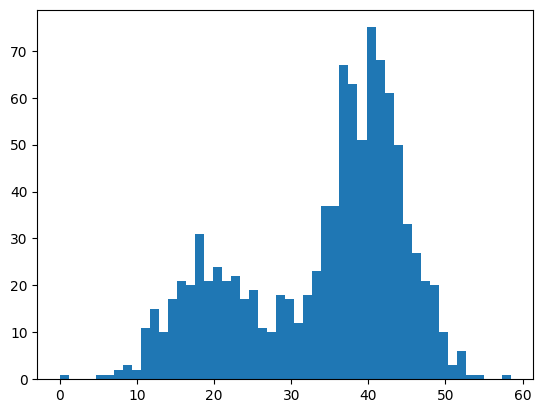

In [22]:
plt.hist(sample,bins=50)

In [23]:
from sklearn.neighbors import KernelDensity

model=KernelDensity(kernel='gaussian',bandwidth=3)
#model.fit(sample)

How to use PDF in data science

In [24]:
dataset=sns.load_dataset("iris")

In [25]:
dataset.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<Axes: xlabel='sepal_length', ylabel='Density'>

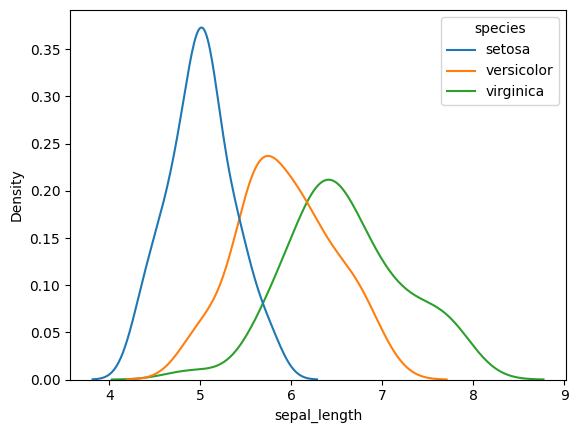

In [26]:
sns.kdeplot(data=dataset,x="sepal_length",hue=dataset["species"])

<Axes: xlabel='sepal_width', ylabel='Density'>

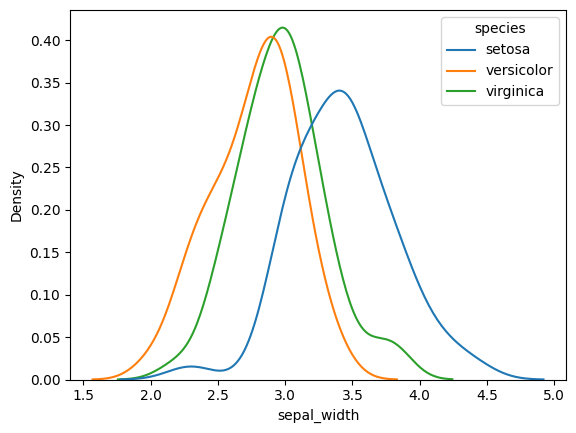

In [27]:
sns.kdeplot(data=dataset,x="sepal_width",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

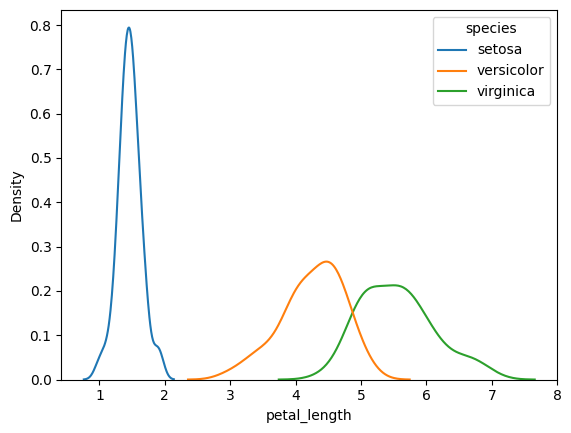

In [28]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

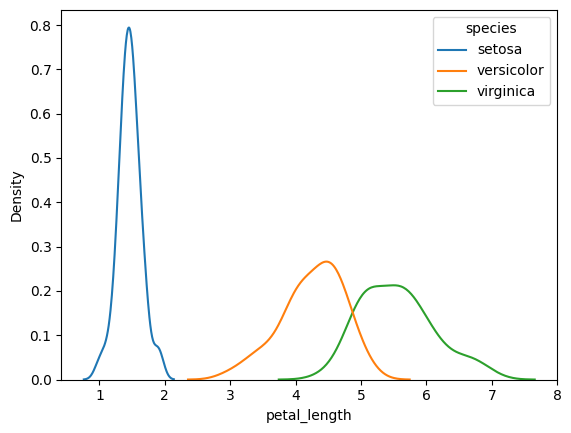

In [29]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

In [30]:
tips=sns.load_dataset("tips")

In [31]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<Axes: xlabel='tip', ylabel='Density'>

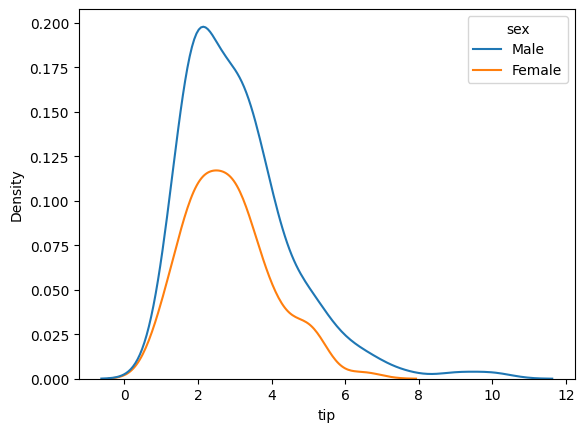

In [32]:
sns.kdeplot(data=tips,x="tip",hue="sex")

<Axes: xlabel='petal_width', ylabel='Density'>

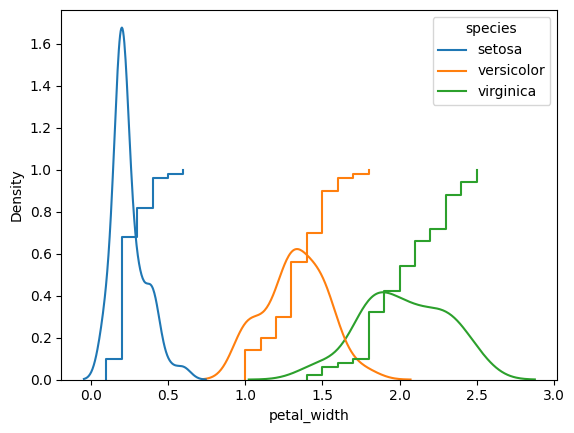

In [33]:
sns.kdeplot(data=dataset,x="petal_width",hue=dataset["species"])
sns.ecdfplot(data=dataset,x="petal_width",hue=dataset["species"])

2D density plots

In [34]:
#contour plots

How to find distribution is normal or not?

In [35]:
iris=sns.load_dataset("iris")

<Axes: xlabel='sepal_length', ylabel='Density'>

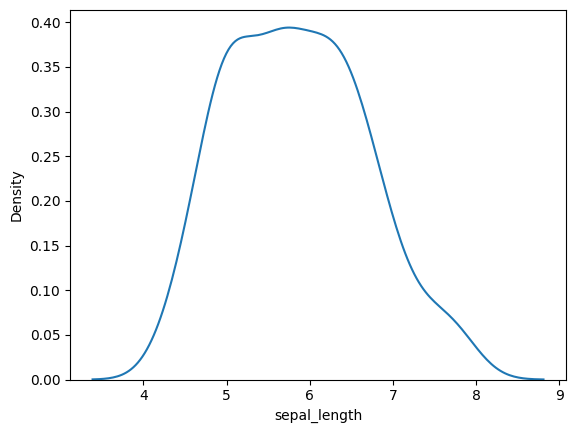

In [36]:
sns.kdeplot(iris["sepal_length"])

In [37]:
temp=sorted(iris['sepal_length'].tolist())

In [38]:
y_quant=[]

for i in range(1,101):
  y_quant.append(np.percentile(temp,i))

In [39]:
samples=np.random.normal(loc=0,scale=1,size=1000)

In [40]:
x_quant=[]

for i in range(1,101):
  x_quant.append(np.percentile(samples,i))

<Axes: >

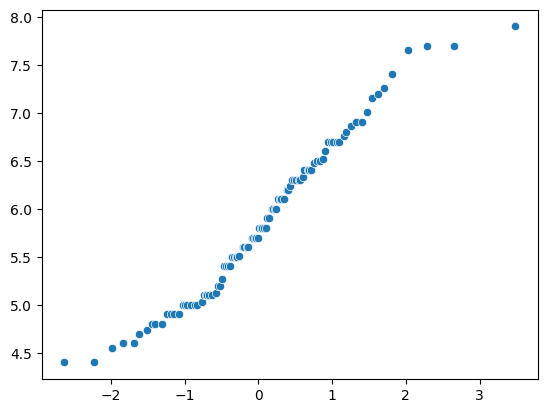

In [41]:
sns.scatterplot(x=x_quant,y=y_quant)

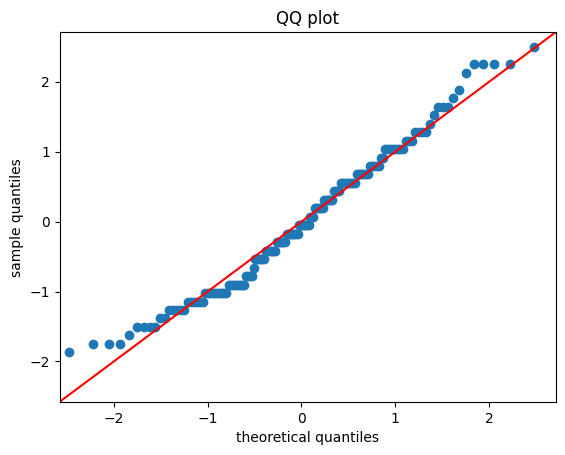

In [42]:
#using statsmodel

import statsmodels.api as sm

#create QQplot of two sets of data
fig=sm.qqplot(iris['sepal_length'],line='45',fit=True)

plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()